# Final Project: End-to-End Twitter Sentiment Analysis System

**Student:** Hiren Patel | **Program:** DAAI (Data Analytics and Artificial Intelligence), Willis College

## Introduction

Every day, people share their opinions about products, brands, events and services on social media. For a business, these opinions are valuable feedback, but there are far too many to read by hand. A sentiment analysis system solves this by automatically reading a short piece of text and deciding whether the writer feels positive, negative or neutral about something. A marketing team can use it to track how customers react to a new campaign, a support team can use it to spot angry customers early, and a product team can use it to measure how a launch is received.

In this project I build a complete sentiment analysis system the way a machine learning engineer would in a real company, not just a model in a notebook. First, I clean and prepare historical Twitter data, train a logistic regression model, and check its quality on data it has never seen. Then I turn the model into a web service with Flask, so that any application can send a tweet and get its sentiment back. I package this service in a Docker container so it runs the same way on any machine, and publish the image to Docker Hub. To make the system reliable over time, I add automated testing and deployment with GitHub Actions, document how models are versioned and how to roll back to an older version, and finally deploy the service on Kubernetes, which keeps it running and scales it up or down automatically when traffic changes.

This notebook covers the data and model part of the project. The API, container, CI/CD (Continuous Integration and Continuous Deployment) pipeline and Kubernetes deployment are in the other folders of this repository and are explained in the project report.

In [1]:
# I import the libraries and print versions (the API container must use the same scikit-learn version)
import sys, time, json, hashlib, os
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

sys.path.append("..")                       # I make the shared src/ folder importable
from src.preprocess import clean_tweet, tokenize, preprocess

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)
DATA_PATH = "../data/training.1600000.processed.noemoticon.csv"
MODEL_DIR = "../models"
RANDOM_STATE = 0

Python: 3.14.2
pandas: 3.0.2 | numpy: 2.4.4 | scikit-learn: 1.8.0


**Interpretation:** My laptop runs Python 3.14.2 with pandas 3.0.2, NumPy 2.4.4 and scikit-learn 1.8.0. The scikit-learn version is important: a model saved with scikit-learn 1.8.0 must be loaded with the same version, so the Docker container for the API will pin exactly scikit-learn 1.8.0.

## 1. Load the data

The file has no header row, so I name the six columns myself. The text uses the Latin-1 encoding (not UTF-8), so I have to tell pandas that, otherwise some tweets fail to load. The label column uses **0 = negative** and **4 = positive**, which I convert to **0** and **1**.

In [2]:
t0 = time.time()
cols = ["target", "id", "date", "flag", "user", "text"]
df = pd.read_csv(DATA_PATH, encoding="latin-1", header=None, names=cols)
df["label"] = (df["target"] == 4).astype(int)        # 1 = positive, 0 = negative
print(f"Loaded in {time.time() - t0:.1f} s")
print("Shape:", df.shape)
print("\nOriginal target values:", df["target"].value_counts().to_dict())
print("Missing values per column:", df.isna().sum().to_dict())
print("Unique values in 'flag':", df["flag"].unique())
df.head()

Loaded in 2.2 s
Shape: (1600000, 7)

Original target values: {0: 800000, 4: 800000}
Missing values per column: {'target': 0, 'id': 0, 'date': 0, 'flag': 0, 'user': 0, 'text': 0, 'label': 0}
Unique values in 'flag': <ArrowStringArray>
['NO_QUERY']
Length: 1, dtype: str


,target,id,date,flag,user,text,label
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t...",0
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...,0
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...,0
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire,0
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all....",0


**Interpretation:** The file loaded in about 2 seconds and has 1,600,000 tweets. It is perfectly balanced: 800,000 negative (0) and 800,000 positive (4) tweets, and there are no missing values in any column. The `flag` column has only one value (`NO_QUERY`), so it carries no information. The `id`, `date` and `user` columns describe the tweet, not its feeling, so I only use the `text` column as input and `label` as the answer.

In [3]:
# I check duplicates and conflicting labels
dup_rows = df.duplicated(subset=["text", "label"]).sum()
conflicts = df.groupby("text")["label"].nunique()
n_conflict_texts = (conflicts > 1).sum()
print("Exact duplicate tweets (same text and label):", dup_rows)
print("Texts that appear with BOTH labels:", n_conflict_texts)

df["n_words_raw"] = df["text"].str.split().str.len()
print("\nWords per raw tweet:"); print(df["n_words_raw"].describe().round(1))

Exact duplicate tweets (same text and label): 16309
Texts that appear with BOTH labels: 2225

Words per raw tweet:
count    1600000.0
mean          13.2
std            7.0
min            1.0
25%            7.0
50%           12.0
75%           19.0
max           64.0
Name: n_words_raw, dtype: float64


**Interpretation:** 16,309 tweets appear more than once with the same label, and 2,225 texts appear with **both** labels. Duplicates would let the same tweet sit in both the training and the test set, which makes the score look better than it really is. Contradictory labels simply confuse the model. Tweets are short: on average 13.2 words, half of them 12 words or fewer, and at most 64 words, which fits Twitter's 140-character limit in 2009.

## 2. Inspect the tweet text before cleaning

In [4]:
# I measure how often each kind of "noise" appears in the raw tweets, so my cleaning is based on evidence
import re
patterns = {
    "URL (http/www)":             r"https?://\S+|www\.\S+",
    "@mention":                   r"@\w+",
    "#hashtag":                   r"#\w+",
    "HTML entity (&amp; &quot;)": r"&\w+;",
    "apostrophe (can't, I'm)":    r"\w'\w",
    "letter repeated 3+ times":   r"([a-zA-Z])\1{2,}",
    "digits":                     r"\d",
    "punctuation !?.,":           r"[!?.,]",
    "uppercase word":             r"\b[A-Z]{2,}\b",
    "non-English characters":     r"[^\x00-\x7F]",
}
texts = df["text"].tolist()
rows = []
for name, pat in patterns.items():
    rx = re.compile(pat)
    hits = np.fromiter((rx.search(t) is not None for t in texts), dtype=bool, count=len(texts))
    example = texts[int(np.argmax(hits))][:90] if hits.any() else ""
    rows.append({"pattern": name, "tweets_with_it": int(hits.sum()), "share_%": round(100 * hits.mean(), 1), "example": example})
noise = pd.DataFrame(rows).sort_values("tweets_with_it", ascending=False).reset_index(drop=True)
pd.set_option("display.max_colwidth", 95)
noise

,pattern,tweets_with_it,share_%,example
0,"punctuation !?.,",1240184,77.5,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr"
1,@mention,738493,46.2,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr"
2,"apostrophe (can't, I'm)",472468,29.5,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr"
3,digits,366487,22.9,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr"
4,uppercase word,233728,14.6,"@LOLTrish hey long time no see! Yes.. Rains a bit ,only a bit LOL , I'm fine thanks , ho"
5,letter repeated 3+ times,144263,9.0,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr"
6,HTML entity (&amp; &quot;),94458,5.9,watching &quot;House&quot;
7,URL (http/www),75693,4.7,"@switchfoot http://twitpic.com/2y1zl - Awww, that's a bummer. You shoulda got David Carr"
8,#hashtag,35847,2.2,@markhardy1974 Me too #itm
9,non-English characters,14538,0.9,"@JonathanRKnight I hate the limited letters,too.Hope you and the guys are fine?I pray for"


Before I decide how to clean the tweets, I need to know what is actually inside them. This cell searches all 1.6 million raw tweets for typical Twitter "noise": links, @mentions, hashtags, HTML codes such as `&amp;`, contractions, stretched words, numbers, punctuation, CAPITAL words and non-English characters. The cleaning steps in the next section are chosen based on these results.

**Interpretation:** Punctuation appears in 77.5% of tweets and @mentions in 46.2%, so almost half of the tweets talk to another user. 29.5% contain apostrophes (can't, I'm), 22.9% contain numbers, and 14.6% contain words in CAPITALS. Stretched words like "Awww" appear in 9.0% of tweets, HTML codes such as `&quot;` in 5.9%, links in 4.7%, hashtags in 2.2%, and non-English characters in only 0.9%. This tells me which cleaning steps matter most. @mentions and links must go, because a username or a link says nothing about feelings. Apostrophes need careful handling, because many of them are negations like "can't" and "don't", which are important for sentiment.

## 3. Clean and preprocess the tweets

In [5]:
# I show the cleaning on a few real tweets before applying it to all of them
examples = df.sample(6, random_state=RANDOM_STATE)["text"].tolist() + \
           ["@user I CAN'T believe it!!! Sooooo happy #blessed http://t.co/xyz &amp; more"]
for t in examples:
    print("RAW   :", t)
    print("TOKENS:", tokenize(t))
    print()

RAW   : wants to compete! i want hard competition! i want to rally. i want to feel the power coming out of the engine! i want to compete 
TOKENS: ['wants', 'to', 'compete', 'i', 'want', 'hard', 'competition', 'i', 'want', 'to', 'rally', 'i', 'want', 'to', 'feel', 'the', 'power', 'coming', 'out', 'of', 'the', 'engine', 'i', 'want', 'to', 'compete']

RAW   : It seems we are stuck on the ground in Amarillo. They have put a ground stop for all flights leaving for Denver. Said updates in an hour 
TOKENS: ['it', 'seems', 'we', 'are', 'stuck', 'on', 'the', 'ground', 'in', 'amarillo', 'they', 'have', 'put', 'a', 'ground', 'stop', 'for', 'all', 'flights', 'leaving', 'for', 'denver', 'said', 'updates', 'in', 'an', 'hour']

RAW   : where the f are my pinking shears? rarararrrarararr...babyproofing while cutting stuff makes me stick shears random places &amp; forget them 
TOKENS: ['where', 'the', 'are', 'my', 'pinking', 'shears', 'rarararrarararr', 'babyproofing', 'while', 'cutting', 'stuff', 'mak

**Interpretation:** The cleaning works as planned. Mentions, links, `&amp;` and punctuation disappear, "CAN'T" becomes "cant", "Sooooo" becomes "soo", and "#blessed" keeps the word "blessed". The examples also show two small weaknesses. People who write with zeros instead of the letter o ("0ff t0 tHE MEEtiN", "V0lUNtEER") lose part of the word ("ff", "lunteer"), because I remove digits. And a censored word like "the f" loses the "f", because single letters are dropped. These cases are rare and have little effect on the overall result.

In [6]:
t0 = time.time()
df["clean"] = df["text"].map(preprocess)
print(f"Cleaned {len(df):,} tweets in {time.time() - t0:.1f} s")

before = len(df)
df = df[df["clean"].str.len() > 0]                                # tweets that became empty
empty_removed = before - len(df)
df = df.drop_duplicates(subset=["clean", "label"])                # repeated tweets
conflict = df.groupby("clean")["label"].transform("nunique") > 1  # same text, both labels
df = df[~conflict]
print("Removed empty after cleaning:", empty_removed)
print("Rows after removing duplicates and conflicting labels:", len(df), f"(removed {before - len(df):,} in total)")
print("Label balance now:", df["label"].value_counts(normalize=True).round(4).to_dict())
df["n_tokens"] = df["clean"].str.split().str.len()

Cleaned 1,600,000 tweets in 9.2 s
Removed empty after cleaning: 3806
Rows after removing duplicates and conflicting labels: 1510511 (removed 89,489 in total)
Label balance now: {0: 0.5034, 1: 0.4966}


**Interpretation:** Cleaning all 1.6 million tweets took only 9.2 seconds. 3,806 tweets became empty, because they contained nothing but mentions, links or symbols, so I removed them. Together with the duplicates and contradictory texts, 89,489 rows (5.6%) were removed, leaving 1,510,511 tweets. The classes are still almost perfectly balanced, at 50.3% negative and 49.7% positive.

In [7]:
# I run the same checks on the CLEANED text to prove the noise is gone
clean_texts = df["clean"].tolist()
check = []
for name, pat in patterns.items():
    rx = re.compile(pat)
    left = sum(rx.search(t) is not None for t in clean_texts)
    check.append({"pattern": name, "raw_tweets_with_it": int(noise.set_index("pattern").loc[name, "tweets_with_it"]), "after_cleaning": left})
pd.DataFrame(check)

,pattern,raw_tweets_with_it,after_cleaning
0,URL (http/www),75693,0
1,@mention,738493,0
2,#hashtag,35847,0
3,HTML entity (&amp; &quot;),94458,0
4,"apostrophe (can't, I'm)",472468,0
5,letter repeated 3+ times,144263,0
6,digits,366487,0
7,"punctuation !?.,",1240184,0
8,uppercase word,233728,0
9,non-English characters,14538,0


Each cleaning step answers a problem I found in section 2. Almost half of the tweets contain @mentions, and about 5% contain links. These carry no sentiment, so I remove them. About 6% contain HTML codes like `&amp;`, which I decode. Almost 30% use apostrophes, so I keep negations like "can't" as one word. About 9% stretch words like "sooooo", which I shorten so they match each other.

The cleaning function lives in `src/preprocess.py`, so that the **Flask API uses exactly the same code** as the training notebook. If training and serving cleaned text differently, the model would see different inputs in production. This problem is called training/serving skew. The steps are:

1. Decode HTML entities (`&amp;` becomes `&`) and convert everything to lowercase
2. Remove URLs and @mentions
3. Keep hashtag words but drop the `#` symbol
4. Remove apostrophes so that negations like "can't" become "cant" instead of being split into "can" and "t"
5. Shorten letters repeated 3 or more times ("sooooo" becomes "soo")
6. Remove numbers, emojis, punctuation and other special characters
7. Tokenize: split the text into words and drop one-letter tokens (except "i" and "a")

**Interpretation:** This is the proof that the cleaning did its job: every type of noise I counted before (links, mentions, hashtags, HTML codes, apostrophes, stretched letters, digits, punctuation, capitals and non-English characters) now appears in **0** tweets. The text that goes into the model is consistent lowercase words only.

## 4. Explore the cleaned data

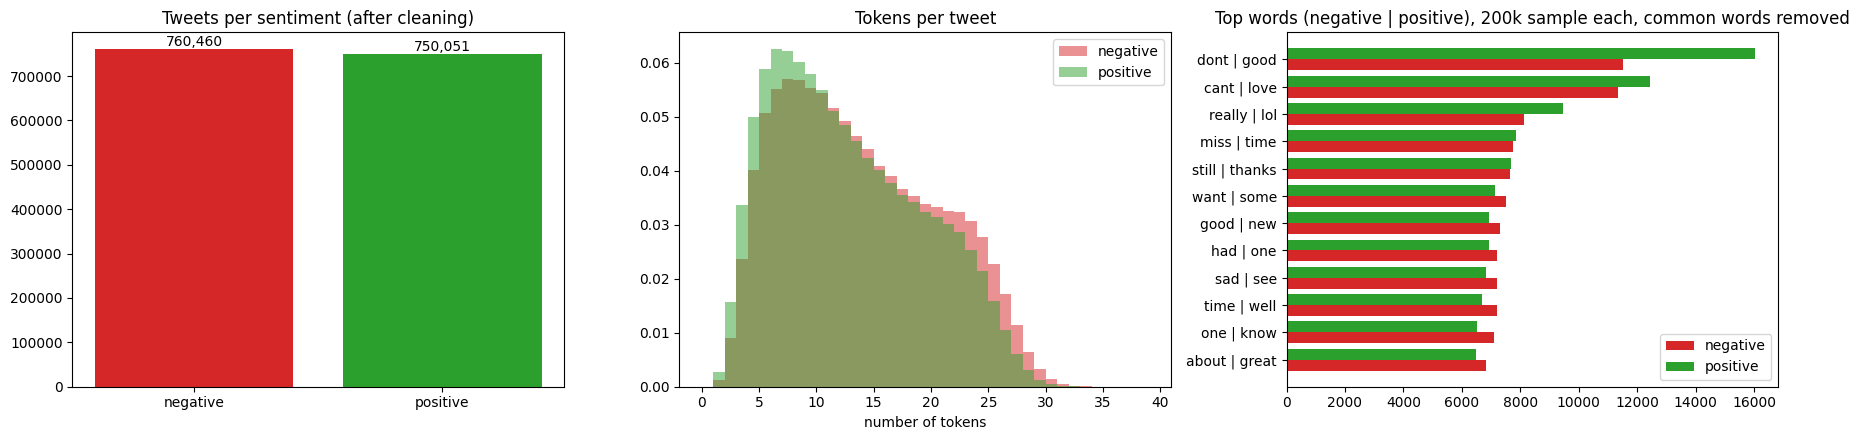

Median tokens - negative: 12.0 | positive: 11.0


In [8]:
from collections import Counter
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

counts = df["label"].map({0: "negative", 1: "positive"}).value_counts()
bars = axes[0].bar(counts.index, counts.values, color=["tab:red", "tab:green"])
axes[0].bar_label(bars, fmt="{:,.0f}"); axes[0].set_title("Tweets per sentiment (after cleaning)")

for lab, color, name in [(0, "tab:red", "negative"), (1, "tab:green", "positive")]:
    axes[1].hist(df.loc[df.label == lab, "n_tokens"], bins=range(0, 40), alpha=0.5, color=color, label=name, density=True)
axes[1].set_title("Tokens per tweet"); axes[1].set_xlabel("number of tokens"); axes[1].legend()

stop = {"i","a","the","to","and","my","it","is","in","for","of","you","on","me","so","that","have","but",
        "just","at","be","with","was","not","im","its","this","get","all","up","are","out","now","go","day",
        "no","do","too","got","what","like","will","we","am","going","today","work","can","back","from","your"}
def top_words(lab, n=12):
    c = Counter(w for s in df.loc[df.label == lab, "clean"].sample(200000, random_state=RANDOM_STATE) for w in s.split() if w not in stop)
    return pd.Series(dict(c.most_common(n)))
neg_top, pos_top = top_words(0), top_words(1)
y = np.arange(12)
axes[2].barh(y + 0.2, neg_top.values, 0.4, color="tab:red", label="negative")
axes[2].barh(y - 0.2, pos_top.values, 0.4, color="tab:green", label="positive")
axes[2].set_yticks(y); axes[2].set_yticklabels([f"{a} | {b}" for a, b in zip(neg_top.index, pos_top.index)])
axes[2].invert_yaxis(); axes[2].set_title("Top words (negative | positive), 200k sample each, common words removed")
axes[2].legend()
plt.tight_layout(); plt.savefig("../reports/eda.png", dpi=100); plt.show()
print("Median tokens - negative:", df.loc[df.label == 0, "n_tokens"].median(), "| positive:", df.loc[df.label == 1, "n_tokens"].median())

**Interpretation:** The left chart confirms that the cleaned data is still balanced (760,460 negative and 750,051 positive tweets), so the model does not need class weights. The middle chart shows that positive tweets are slightly shorter (median 11 tokens vs 12 for negative), and that negative tweets have a longer tail of 20 to 30 tokens: people tend to write more when they complain. The right chart shows the most frequent words. Negative tweets are dominated by "dont", "cant", "miss", "still", "want" and "sad", while positive tweets use "good", "love", "lol", "thanks", "new" and "great". The word "good" also appears in the negative list (for example "not good" or "good night, I'm so tired"), which shows that single words are not enough. This is why I also use word pairs in the model.

## 5. Train / validation / test split



In [9]:
X, y = df["clean"].to_numpy(dtype=object), df["label"].to_numpy()
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} | Validation: {len(X_val):,} | Test: {len(X_test):,}")
print("Positive share:", round(y_train.mean(), 4), round(y_val.mean(), 4), round(y_test.mean(), 4))

Train: 1,208,408 | Validation: 151,051 | Test: 151,052
Positive share: 0.4966 0.4966 0.4966


I split the data into three parts, stratified so that each part keeps the 50/50 balance:
- **Train (80%):** the model learns from this part.
- **Validation (10%):** I use it to choose the settings (the regularisation strength C and the neutral band).
- **Test (10%):** I touch this only once, at the very end, to get an honest final score.

**Interpretation:** The model learns from 1,208,408 tweets, and 151,051 tweets each are kept aside for validation and for the final test. The positive share is exactly 0.4966 in all three parts, so the stratified split kept the same balance everywhere and the three scores can be compared fairly.

## 6. Features and logistic regression



In [10]:
t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=300_000, sublinear_tf=True, dtype=np.float32)
Xtr = tfidf.fit_transform(X_train)
Xva = tfidf.transform(X_val)
print(f"TF-IDF fitted in {time.time() - t0:.1f} s | vocabulary size: {len(tfidf.vocabulary_):,}")
print("Train matrix:", Xtr.shape, "| non-zero values:", f"{Xtr.nnz:,}")

tuning = []
for C in [0.25, 0.5, 1.0, 2.0]:
    t0 = time.time()
    lr = LogisticRegression(C=C, solver="liblinear", max_iter=1000)
    lr.fit(Xtr, y_train)
    p = lr.predict(Xva)
    tuning.append({"C": C, "val_accuracy": accuracy_score(y_val, p), "val_f1": f1_score(y_val, p),
                   "train_accuracy": accuracy_score(y_train[:200_000], lr.predict(Xtr[:200_000])),
                   "fit_seconds": time.time() - t0})
tuning = pd.DataFrame(tuning)
best_C = float(tuning.loc[tuning["val_f1"].idxmax(), "C"])
print("Best C on validation:", best_C)
tuning.round(4)

TF-IDF fitted in 23.2 s | vocabulary size: 300,000
Train matrix: (1208408, 300000) | non-zero values: 23,626,186
Best C on validation: 1.0


,C,val_accuracy,val_f1,train_accuracy,fit_seconds
0,0.25,0.8150,0.8155,0.8303,11.4402
1,0.50,0.8191,0.8196,0.8414,14.0329
2,1.00,0.8219,0.8224,0.8528,17.2194
3,2.00,0.8218,0.8223,0.8653,25.3175


**Interpretation:** TF-IDF built a vocabulary of 300,000 words and word pairs in 23 seconds. The training matrix has 1.2 million rows and 300,000 columns, but only 23.6 million non-zero values, about 20 per tweet. More than 99.99% of the matrix is empty, which is why it is stored as a sparse matrix. On the validation set, accuracy rises from 0.8150 (C = 0.25) to 0.8219 (C = 1.0) and then stays flat at C = 2.0 (0.8218). Training accuracy keeps climbing (from 0.830 to 0.865), so a larger C only memorises the training data more without helping new tweets: this is the start of overfitting. C = 1.0 gives the best validation F1 with a small train-validation gap of about 3 points, so I keep it.

In [11]:
# I train the final model with the best C and build one pipeline object (TF-IDF + model)
model = LogisticRegression(C=best_C, solver="liblinear", max_iter=1000).fit(Xtr, y_train)
pipeline = Pipeline([("tfidf", tfidf), ("clf", model)])

val_prob = model.predict_proba(Xva)[:, 1]
val_pred = (val_prob >= 0.5).astype(int)
val_metrics = {"accuracy": accuracy_score(y_val, val_pred), "f1": f1_score(y_val, val_pred),
               "precision": precision_score(y_val, val_pred), "recall": recall_score(y_val, val_pred),
               "roc_auc": roc_auc_score(y_val, val_prob)}
print("VALIDATION:", {k: round(v, 4) for k, v in val_metrics.items()})
print(classification_report(y_val, val_pred, target_names=["negative", "positive"], digits=4))

VALIDATION: {'accuracy': 0.8219, 'f1': 0.8224, 'precision': 0.8145, 'recall': 0.8306, 'roc_auc': 0.9009}
              precision    recall  f1-score   support

    negative     0.8296    0.8134    0.8214     76046
    positive     0.8145    0.8306    0.8224     75005

    accuracy                         0.8219    151051
   macro avg     0.8220    0.8220    0.8219    151051
weighted avg     0.8221    0.8219    0.8219    151051



**TF-IDF (Term Frequency-Inverse Document Frequency)** turns each tweet into a vector of numbers. Words that appear in a tweet get a weight, and words that are common in every tweet (like "the") get a lower weight than distinctive words (like "love" or "hate"). I use single words **and word pairs** (bigrams), so phrases like "not good" or "cant wait" are learned as units. I keep words that appear in at least 5 tweets, up to 300,000 features.

**Logistic regression** learns one weight per feature. A positive weight pushes a tweet towards positive, and a negative weight pushes it towards negative. It is fast, easy to explain, and a strong baseline for text classification.

I fit TF-IDF once on the training set, then try several values of **C** (smaller C = stronger regularisation = simpler model) and pick the best one on the **validation** set.

**Interpretation:** On the validation set the final model reaches **82.19% accuracy and an F1-score of 0.8224**. The ROC AUC (Area Under the ROC Curve) of 0.90 means that, for a random positive and a random negative tweet, the model gives the positive one the higher score 90% of the time. Both classes are handled equally well (F1 0.821 for negative and 0.822 for positive). The model leans very slightly towards "positive": recall for positive tweets is 0.831, compared with 0.813 for negative. For a simple linear model on noisy tweets, about 82% is a strong result. The published benchmark for this dataset with similar models is around 80 to 83%.

## 7. Adding the neutral class

  neutral_band  share_neutral  accuracy_on_rest
0    0.50-0.50         0.0000            0.8219
1    0.45-0.55         0.0637            0.8410
2    0.40-0.60         0.1280            0.8602
3    0.35-0.65         0.1960            0.8786
4    0.30-0.70         0.2693            0.8967
5    0.25-0.75         0.3472            0.9124

Probability for an empty tweet: 0.672 -> chosen neutral band: 0.3-0.7


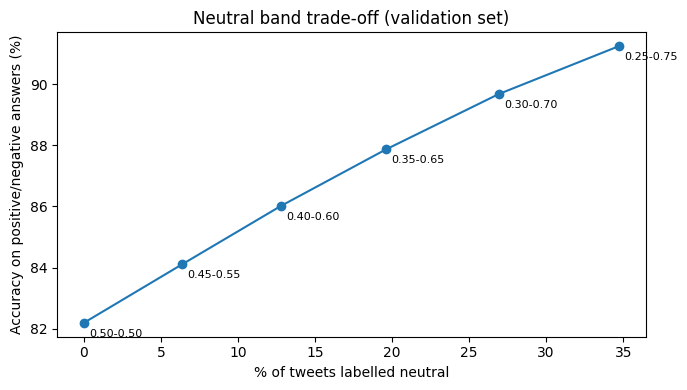

,tweet,prob_positive,sentiment
0,"I love this phone, the camera is amazing!",0.976,positive
1,Worst customer service ever. Never buying again.,0.074,negative
2,Going to the store at 5pm.,0.690,neutral
3,The meeting is on Tuesday.,0.671,neutral
4,The report is attached,0.527,neutral
5,this is ok,0.496,neutral
6,"not bad at all, actually pretty good",0.976,positive
7,I can't wait for the weekend!!!,0.950,positive
8,It is raining today,0.117,negative
9,I have an exam tomorrow,0.102,negative


In [12]:
rows = []
for half_width in [0.0, 0.05, 0.10, 0.15, 0.20, 0.25]:
    lo, hi = 0.5 - half_width, 0.5 + half_width
    confident = (val_prob < lo) | (val_prob > hi)
    rows.append({"neutral_band": f"{lo:.2f}-{hi:.2f}", "share_neutral": 1 - confident.mean(),
                 "accuracy_on_rest": accuracy_score(y_val[confident], val_pred[confident])})
band = pd.DataFrame(rows)
print(band.round(4))

# I choose the band in a principled way: a tweet with NO words must come out neutral.
# For an empty tweet the model only has its intercept (its starting point), so I measure that probability
# and take the smallest symmetric band around 0.5 (in steps of 0.05) that contains it.
p_empty = pipeline.predict_proba([""])[0, 1]
half = np.ceil(abs(p_empty - 0.5) / 0.05) * 0.05
NEUTRAL_LOW, NEUTRAL_HIGH = round(0.5 - half, 2), round(0.5 + half, 2)
print()
print(f"Probability for an empty tweet: {p_empty:.3f} -> chosen neutral band: {NEUTRAL_LOW}-{NEUTRAL_HIGH}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(band["share_neutral"] * 100, band["accuracy_on_rest"] * 100, marker="o")
for _, r in band.iterrows():
    ax.annotate(r["neutral_band"], (r["share_neutral"] * 100, r["accuracy_on_rest"] * 100), fontsize=8, xytext=(4, -10), textcoords="offset points")
ax.set_xlabel("% of tweets labelled neutral"); ax.set_ylabel("Accuracy on positive/negative answers (%)")
ax.set_title("Neutral band trade-off (validation set)")
plt.tight_layout(); plt.savefig("../reports/neutral_tradeoff.png", dpi=100); plt.show()

def to_sentiment(prob, lo=NEUTRAL_LOW, hi=NEUTRAL_HIGH):
    return np.where(prob > hi, "positive", np.where(prob < lo, "negative", "neutral"))

demo = ["I love this phone, the camera is amazing!",
        "Worst customer service ever. Never buying again.",
        "Going to the store at 5pm.",
        "The meeting is on Tuesday.",
        "The report is attached",
        "this is ok",
        "not bad at all, actually pretty good",
        "I can't wait for the weekend!!!",
        "It is raining today",
        "I have an exam tomorrow"]
demo_prob = pipeline.predict_proba([preprocess(t) for t in demo])[:, 1]
pd.DataFrame({"tweet": demo, "prob_positive": demo_prob.round(3), "sentiment": to_sentiment(demo_prob)})

The training labels only contain **positive** and **negative** tweets, but the project needs a third answer, **neutral**. Instead of guessing, I use the model's **confidence**. Logistic regression gives a probability that a tweet is positive. When that probability is close to 0.5, the model is unsure, because the tweet has no strong positive or negative words (for example "going to the store at 5"). I label those tweets **neutral**.

First I look at the trade-off on the validation set: a wider band makes the remaining positive and negative answers more accurate, but more tweets get called neutral. Then I choose the band with a simple rule: a tweet with **no sentiment words at all** must come out as neutral. I measure the probability the model gives to an empty tweet and use the smallest symmetric band around 0.5 that contains it.

**Interpretation:** The table shows the trade-off. With no neutral band, every tweet gets an answer and accuracy is 82.2%. A band of 0.30-0.70 labels 26.9% of tweets as neutral, and accuracy on the remaining positive and negative answers rises to 89.7%. An empty tweet gets a probability of 0.672 (this is the model's intercept, its starting point), so 0.30-0.70 is the smallest band that contains it, and that is the band I use. The demo shows that the system now behaves sensibly. Clear opinions are classified correctly ("love this phone" is positive at 0.976, "worst customer service" is negative at 0.074, and "not bad at all" is positive at 0.976). Factual sentences like "The meeting is on Tuesday", "Going to the store at 5pm" and "The report is attached" come out **neutral**, and so does "this is ok". "It is raining today" and "I have an exam tomorrow" come out negative, because in 2009 Twitter data people mostly mentioned rain and exams when complaining, and the model learned that pattern.

## 8. Final evaluation on the untouched test set

TEST: {'accuracy': 0.8231, 'f1': 0.8236, 'precision': 0.8157, 'recall': 0.8316, 'roc_auc': 0.9018, 'share_neutral': np.float64(0.2679), 'accuracy_excluding_neutral': 0.8966}
              precision    recall  f1-score   support

    negative     0.8307    0.8146    0.8226     76046
    positive     0.8157    0.8316    0.8236     75006

    accuracy                         0.8231    151052
   macro avg     0.8232    0.8231    0.8231    151052
weighted avg     0.8232    0.8231    0.8231    151052



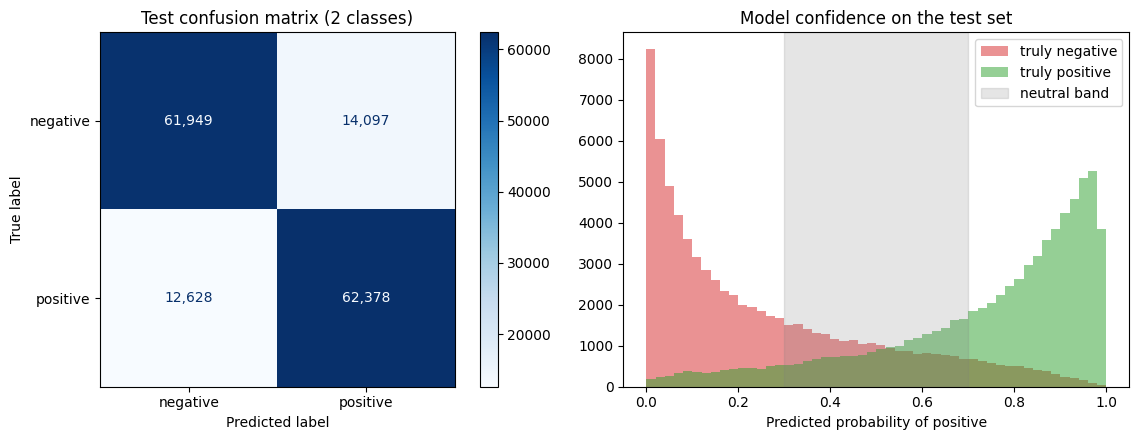

In [13]:
test_prob = pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
test_metrics = {"accuracy": accuracy_score(y_test, test_pred), "f1": f1_score(y_test, test_pred),
                "precision": precision_score(y_test, test_pred), "recall": recall_score(y_test, test_pred),
                "roc_auc": roc_auc_score(y_test, test_prob)}
conf = (test_prob < NEUTRAL_LOW) | (test_prob > NEUTRAL_HIGH)
test_metrics["share_neutral"] = 1 - conf.mean()
test_metrics["accuracy_excluding_neutral"] = accuracy_score(y_test[conf], test_pred[conf])
print("TEST:", {k: round(v, 4) for k, v in test_metrics.items()})
print(classification_report(y_test, test_pred, target_names=["negative", "positive"], digits=4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=["negative", "positive"]).plot(ax=axes[0], cmap="Blues", values_format=",d")
axes[0].set_title("Test confusion matrix (2 classes)")
axes[1].hist(test_prob[y_test == 0], bins=50, alpha=0.5, color="tab:red", label="truly negative")
axes[1].hist(test_prob[y_test == 1], bins=50, alpha=0.5, color="tab:green", label="truly positive")
axes[1].axvspan(NEUTRAL_LOW, NEUTRAL_HIGH, color="grey", alpha=0.2, label="neutral band")
axes[1].set_xlabel("Predicted probability of positive"); axes[1].set_title("Model confidence on the test set"); axes[1].legend()
plt.tight_layout(); plt.savefig("../reports/test_evaluation.png", dpi=100); plt.show()

**Interpretation:** On the untouched test set the model scores **82.31% accuracy, an F1 of 0.8236 and an AUC of 0.902**, almost exactly the same as on validation (82.19%). This means the model generalises well to new tweets, and my choice of C did not overfit the validation set. The confusion matrix shows 61,949 negative and 62,378 positive tweets classified correctly. There are 14,097 negative tweets wrongly called positive and 12,628 positive tweets wrongly called negative, so the two kinds of error are similar in size. The histogram explains why the neutral band works. Most tweets get a confident score near 0 or near 1, and the red and green areas overlap mainly in the middle. The grey neutral band covers exactly this uncertain zone: with it, 26.8% of test tweets are labelled neutral, and the positive and negative answers that remain are correct 89.7% of the time.

## 9. What did the model learn?

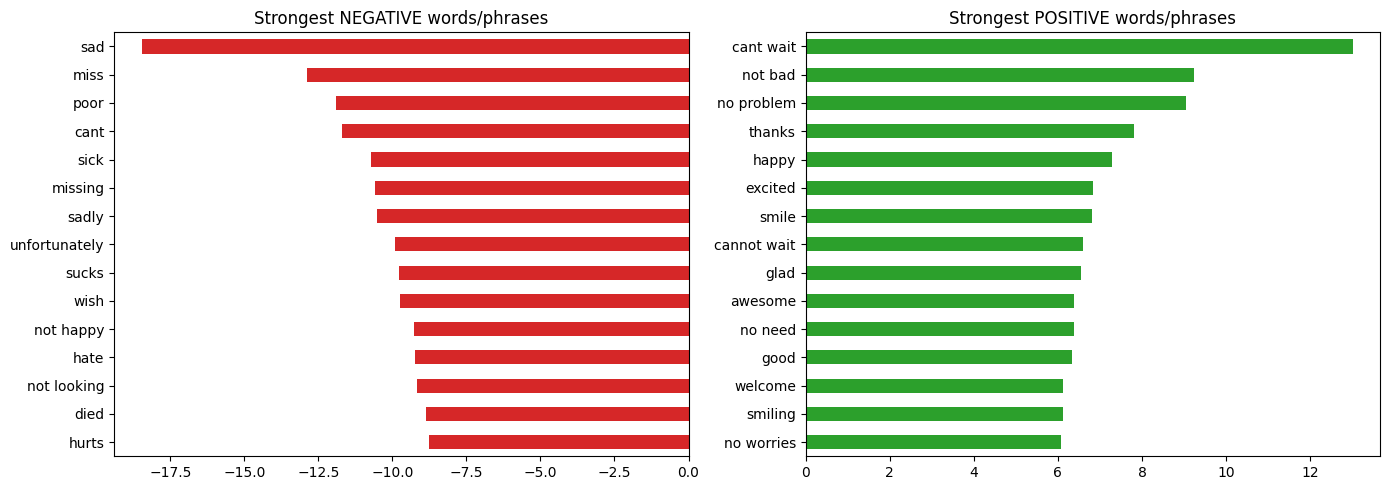

,clean_text,true,prob_positive,error
35317,good lucck love,0,0.999917,0.999917
3749,i guess im stuck at home no dance today but i miss everyone,1,0.000716,0.999284
71811,netballs cancelled,1,0.001151,0.998849
124806,is not very right now missing my sweet friend who broke her leg sniff sniff have tons of studyin to do and wants to ...,1,0.001190,0.998810
119176,i want mencoder,1,0.001734,0.998266
95375,i want a seahorse,1,0.001734,0.998266
133241,ugh im tired i dont want to go back to bed i migh but idk,1,0.001800,0.998200
132652,headache killa cramps ugh newpark mall layytaa,1,0.001811,0.998189


In [14]:
feat = np.array(tfidf.get_feature_names_out())
coef = model.coef_[0]
top_pos = pd.Series(coef, index=feat).nlargest(15)
top_neg = pd.Series(coef, index=feat).nsmallest(15)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_neg.sort_values(ascending=False).plot(kind="barh", ax=axes[0], color="tab:red"); axes[0].set_title("Strongest NEGATIVE words/phrases")
top_pos.sort_values().plot(kind="barh", ax=axes[1], color="tab:green"); axes[1].set_title("Strongest POSITIVE words/phrases")
plt.tight_layout(); plt.savefig("../reports/top_features.png", dpi=100); plt.show()

# I look at the most confident mistakes to understand the model's limits
err = pd.DataFrame({"clean_text": X_test, "true": y_test, "prob_positive": test_prob})
err["error"] = np.abs(err["true"] - err["prob_positive"])
pd.set_option("display.max_colwidth", 120)
err.sort_values("error", ascending=False).head(8)

**Interpretation:** The strongest negative signals are "sad", "miss", "poor", "cant", "sick", "sadly", "unfortunately", "sucks", "hate" and "hurts". The strongest positive signal is the phrase **"cant wait"**, followed by "not bad", "no problem", "thanks", "happy", "excited" and "smile". This proves why word pairs and my apostrophe handling matter. On its own "cant" is strongly negative, but "cant wait" is the most positive phrase in the whole model, and "not bad" and "no problem" are positive even though "bad" and "problem" are negative words. The most confident mistakes show the limits of this dataset. Sentiment140 labels were created automatically from emoticons, so a tweet like "good luck love" is labelled negative, and "i want a seahorse" is labelled positive, probably because of a sad or happy emoticon that was removed from the text. Mixed tweets like "stuck at home, no dance today, but I miss everyone" are hard even for a human. Many of these "errors" are really noisy labels, not model mistakes.

## 10. Save the model with version information

I save the pipeline (TF-IDF + logistic regression) as one file, together with a metadata file that records exactly what this version is. This metadata is the basis of model versioning and rollback, which I explain in `docs/MODEL_VERSIONING.md`.

In [15]:
MODEL_VERSION = "v1"
os.makedirs(MODEL_DIR, exist_ok=True)

# The vectorizer keeps a huge list of removed rare words (stop_words_) that is not needed for prediction
if hasattr(pipeline.named_steps["tfidf"], "stop_words_"):
    delattr(pipeline.named_steps["tfidf"], "stop_words_")

model_path = f"{MODEL_DIR}/sentiment_model_{MODEL_VERSION}.joblib"
joblib.dump(pipeline, model_path, compress=3)
with open(DATA_PATH, "rb") as f:
    data_hash = hashlib.sha256(f.read()).hexdigest()

metadata = {
    "model_version": MODEL_VERSION,
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "algorithm": "TF-IDF (1-2 grams) + LogisticRegression",
    "hyperparameters": {"C": best_C, "min_df": 5, "max_features": 300000, "ngram_range": [1, 2]},
    "neutral_band": [NEUTRAL_LOW, NEUTRAL_HIGH],
    "training_rows": int(len(X_train)),
    "data_file": os.path.basename(DATA_PATH),
    "data_sha256": data_hash,
    "validation_metrics": {k: round(float(v), 4) for k, v in val_metrics.items()},
    "test_metrics": {k: round(float(v), 4) for k, v in test_metrics.items()},
    "python": sys.version.split()[0], "scikit_learn": sklearn.__version__,
}
with open(f"{MODEL_DIR}/sentiment_model_{MODEL_VERSION}.json", "w") as f:
    json.dump(metadata, f, indent=2)

size_mb = os.path.getsize(model_path) / 1e6
loaded = joblib.load(model_path)
t0 = time.time()
for _ in range(1000):
    loaded.predict_proba([preprocess("I really love this new phone")])
latency_ms = (time.time() - t0)
print(f"Saved {model_path} ({size_mb:.1f} MB)")
print(f"Average prediction time for one tweet: {latency_ms:.2f} ms")
print(json.dumps(metadata, indent=2))

Saved ../models/sentiment_model_v1.joblib (5.9 MB)
Average prediction time for one tweet: 0.20 ms
{
  "model_version": "v1",
  "created_at": "2026-10-12T20:45:08",
  "algorithm": "TF-IDF (1-2 grams) + LogisticRegression",
  "hyperparameters": {
    "C": 1.0,
    "min_df": 5,
    "max_features": 300000,
    "ngram_range": [
      1,
      2
    ]
  },
  "neutral_band": [
    0.3,
    0.7
  ],
  "training_rows": 1208408,
  "data_file": "training.1600000.processed.noemoticon.csv",
  "data_sha256": "08cba6317a49528fcd074f9043aafcd5ad6c6be45ede159c4e36cec33af24afe",
  "validation_metrics": {
    "accuracy": 0.8219,
    "f1": 0.8224,
    "precision": 0.8145,
    "recall": 0.8306,
    "roc_auc": 0.9009
  },
  "test_metrics": {
    "accuracy": 0.8231,
    "f1": 0.8236,
    "precision": 0.8157,
    "recall": 0.8316,
    "roc_auc": 0.9018,
    "share_neutral": 0.2679,
    "accuracy_excluding_neutral": 0.8966
  },
  "python": "3.14.2",
  "scikit_learn": "1.8.0"
}


**Interpretation:** The saved model is only 5.9 MB, small enough to put in GitHub and inside a Docker image. One prediction takes about 0.2 milliseconds, so one container could handle thousands of tweets per second. The metadata file records the version (v1), the creation date, the settings, the SHA-256 fingerprint of the training data, the validation and test scores, the neutral band, and the Python and scikit-learn versions. With this information I can always tell exactly which model is running in production, compare it with a newer version, and roll back if needed.

## 11. Conclusion

In this notebook I built the machine learning core of the sentiment analysis system. I started by inspecting the raw tweets and measuring the noise in them: almost half contained @mentions, about 30% contained apostrophes, and some contained links, HTML codes and stretched words. Based on these findings I wrote one shared cleaning function. It removes links, mentions and special characters, lowercases and tokenizes the text, and keeps negations like "can't" intact. I then removed about 89,000 empty, duplicate and contradictory tweets.

A TF-IDF (Term Frequency-Inverse Document Frequency) representation with single words and word pairs, combined with logistic regression (C = 1.0), reached **82.3% accuracy and an F1-score of 0.824** on 151,052 test tweets that the model had never seen, with almost identical results on the validation set. The model learned sensible patterns, including phrases that flip meaning, such as "cant wait", "not bad" and "no problem". Because the dataset has no neutral labels, I added a neutral class based on the model's confidence. Tweets with a positive probability between 0.30 and 0.70 are labelled neutral (about 27% of tweets), and the remaining positive and negative answers are correct about 90% of the time.

The main limitations are the noisy, emoticon-based labels of Sentiment140 and the approximate neutral class. A transformer model such as BERT, or a dataset with human-labelled neutral tweets, would be the next step to improve accuracy. The trained model (5.9 MB, about 0.2 ms per tweet) and its version metadata are saved in the `models/` folder. In the next parts of the project they are served through a Flask API, packaged in Docker, tested and deployed automatically with GitHub Actions, and run on Kubernetes.